In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, balanced_accuracy_score,  classification_report, confusion_matrix
from sklearn.inspection import permutation_importance

In [2]:
df = pd.read_csv('football_players.csv')
print("Dataset Shape:", df.shape)

df.head()

Dataset Shape: (50149, 44)


,country_of_citizenship,date_of_birth,sub_position,position,foot,height_in_cm,contract_expiration_date,international_caps,international_goals,current_club_domestic_competition_id,...,competition_code,name,sub_type,type,country_name,domestic_league_code,confederation,total_clubs,Player_Future_Potential_Score,Player_Future_Potential_Rating
0,Germany,1978-06-09 0:00:00,Centre-Forward,Attack,right,184.0,NaN,4,NaN,IT1,...,serie-a,serie-a,first_tier,domestic_league,Italy,IT1,europa,20.0,89,Outperforming
1,Germany,1980-08-06 0:00:00,Goalkeeper,Goalkeeper,left,190.0,NaN,4,NaN,L1,...,bundesliga,bundesliga,first_tier,domestic_league,Germany,L1,europa,18.0,61,Average
2,Bulgaria,1981-01-30 0:00:00,Centre-Forward,Attack,NaN,NaN,NaN,4,NaN,GR1,...,super-league-1,super-league-1,first_tier,domestic_league,Greece,GR1,europa,14.0,89,Outperforming
3,Brazil,1978-05-08 0:00:00,Centre-Back,Defender,NaN,NaN,NaN,4,NaN,IT1,...,serie-a,serie-a,first_tier,domestic_league,Italy,IT1,europa,20.0,38,Underperforming
4,Germany,1981-03-18 0:00:00,Goalkeeper,Goalkeeper,right,194.0,NaN,4,NaN,L1,...,bundesliga,bundesliga,first_tier,domestic_league,Germany,L1,europa,18.0,33,Underperforming


In [3]:
target = "Player_Future_Potential_Rating"
print(df[target].value_counts())

print("\nMissing Values:")
print(df[target].isnull().sum())

Player_Future_Potential_Rating
Average            25872
Underperforming    16508
Outperforming       7769
Name: count, dtype: int64

Missing Values:
0


In [4]:
numeric_features = [
    "height_in_cm",
    "international_caps",
    "market_value_in_eur",
    "matches_played",
    "total_minutes",
    "total_goals",
    "total_assists",
    "yellow_cards",
    "red_cards"
]

categorical_features = [
    "position",
    "sub_position",
    "foot",
    "competition_code",
    "confederation"
]

features = numeric_features + categorical_features

target = "Player_Future_Potential_Rating"

In [5]:
df["position"] = df["position"].replace("Missing", np.nan)

print("Missing values in target:", df[target].isnull().sum())

print("\nTarget distribution:")
print(df[target].value_counts())

print("\nPercentage distribution:")
print(df[target].value_counts(normalize=True) * 100)

Missing values in target: 0

Target distribution:
Player_Future_Potential_Rating
Average            25872
Underperforming    16508
Outperforming       7769
Name: count, dtype: int64

Percentage distribution:
Player_Future_Potential_Rating
Average            51.590261
Underperforming    32.917905
Outperforming      15.491834
Name: proportion, dtype: float64


In [6]:
df = df.dropna(subset=[target]).copy()

X = df[features].copy()
y = df[target].copy()

print("Input shape:", X.shape)
print("Target shape:", y.shape)

Input shape: (50149, 14)
Target shape: (50149,)


In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 40119
Testing records: 10030


In [8]:
def create_preprocessor():

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ])

    preprocessor = ColumnTransformer([
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features)
    ])

    return preprocessor

In [9]:
model_1 = Pipeline([
    ("preprocessor", create_preprocessor()),
    ("lda", LinearDiscriminantAnalysis(n_components=2)),
    ("classifier", LogisticRegression(max_iter=2000, random_state=42))
])

model_1.fit(X_train, y_train)
y_pred_1 = model_1.predict(X_test)

print("Model 1 training completed!")

Model 1 training completed!


In [10]:
model_2 = Pipeline([
    ("preprocessor", create_preprocessor()),
    ("classifier", RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1))
])

model_2.fit(X_train, y_train)
y_pred_2 = model_2.predict(X_test)

print("Model 2 training completed!")

Model 2 training completed!


In [11]:
def evaluate_model(y_test, predictions, name):

    print("\n", name)
    print("Accuracy:", accuracy_score(y_test, predictions))
    print("Precision:", precision_score(y_test, predictions, average="weighted", zero_division=0))
    print("Recall:", recall_score(y_test, predictions, average="weighted", zero_division=0))
    print("Weighted F1:", f1_score(y_test, predictions, average="weighted"))
    print("Macro F1:", f1_score(y_test, predictions, average="macro"))
    print("Balanced Accuracy:", balanced_accuracy_score(y_test, predictions))
    print("\nClassification Report:")
    print(classification_report(y_test, predictions))


evaluate_model(y_test, y_pred_1, "LDA + Logistic Regression")
evaluate_model(y_test, y_pred_2, "Random Forest")


 LDA + Logistic Regression
Accuracy: 0.7346959122632104
Precision: 0.7369375803190124
Recall: 0.7346959122632104
Weighted F1: 0.7337230303064692
Macro F1: 0.7231104060935584
Balanced Accuracy: 0.7059608680508456

Classification Report:
                 precision    recall  f1-score   support

        Average       0.73      0.78      0.75      5174
  Outperforming       0.80      0.62      0.69      1554
Underperforming       0.72      0.72      0.72      3302

       accuracy                           0.73     10030
      macro avg       0.75      0.71      0.72     10030
   weighted avg       0.74      0.73      0.73     10030


 Random Forest
Accuracy: 0.9318045862412762
Precision: 0.9318669068569367
Recall: 0.9318045862412762
Weighted F1: 0.9317125462530442
Macro F1: 0.9276424633972215
Balanced Accuracy: 0.9223329044086374

Classification Report:
                 precision    recall  f1-score   support

        Average       0.93      0.94      0.93      5174
  Outperforming      

In [12]:
results = []  
for name, predictions in [
    ("LDA + Logistic Regression", y_pred_1),
    ("Random Forest", y_pred_2)
]:

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, average="weighted",zero_division=0),
        "Recall": recall_score(y_test, predictions, average="weighted", zero_division=0),
        "Weighted F1": f1_score(y_test, predictions, average="weighted"),
        "Macro F1": f1_score(y_test, predictions, average="macro")
    })

comparison_df = pd.DataFrame(results)
comparison_df

,Model,Accuracy,Precision,Recall,Weighted F1,Macro F1
0,LDA + Logistic Regression,0.734696,0.736938,0.734696,0.733723,0.723110
1,Random Forest,0.931805,0.931867,0.931805,0.931713,0.927642


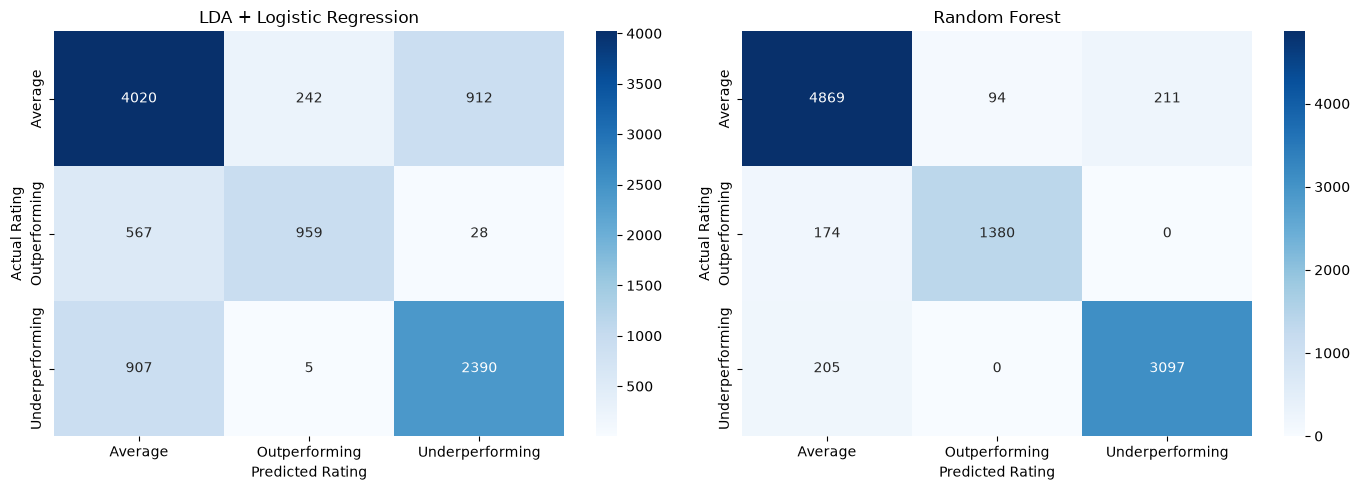

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

labels = [
    "Average",
    "Outperforming",
    "Underperforming"
]

for ax, predictions, title in zip(
    axes,
    [y_pred_1, y_pred_2],
    ["LDA + Logistic Regression", "Random Forest"]
):

    cm = confusion_matrix(y_test, predictions, labels=labels)
    sns.heatmap(cm, annot=True, fmt="d",cmap="Blues", xticklabels=labels, yticklabels=labels, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("Predicted Rating")
    ax.set_ylabel("Actual Rating")

plt.tight_layout()
plt.show()

In [14]:
param_grid_1 = {"classifier__C": [0.01, 0.1, 1, 10, 100]}

grid_search_1 = GridSearchCV(model_1, param_grid_1, cv=3, scoring="f1_weighted", n_jobs=-1)
grid_search_1.fit(X_train, y_train)

print("Best parameters:")
print(grid_search_1.best_params_)

print("Best CV score:")
print(grid_search_1.best_score_)

best_model_1 = grid_search_1.best_estimator_

Best parameters:
{'classifier__C': 1}
Best CV score:
0.7350001141778847


In [15]:
param_grid_2 = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [None, 20],
    "classifier__min_samples_split": [2, 5],
    "classifier__min_samples_leaf": [1, 2]
}

random_search = RandomizedSearchCV(model_2, param_distributions=param_grid_2, n_iter=5, cv=3, scoring="f1_weighted", random_state=42, n_jobs=1)
random_search.fit(X_train, y_train)

print("Best parameters:")
print(random_search.best_params_)

print("Best CV score:")
print(random_search.best_score_)

best_model_2 = random_search.best_estimator_

Best parameters:
{'classifier__n_estimators': 200, 'classifier__min_samples_split': 2, 'classifier__min_samples_leaf': 2, 'classifier__max_depth': 20}
Best CV score:
0.933716840112217


In [16]:
best_pred_1 = best_model_1.predict(X_test)
best_pred_2 = best_model_2.predict(X_test)

evaluate_model(y_test, best_pred_1, "Tuned LDA + Logistic Regression")
evaluate_model(y_test, best_pred_2, "Tuned Random Forest")


 Tuned LDA + Logistic Regression
Accuracy: 0.7346959122632104
Precision: 0.7369375803190124
Recall: 0.7346959122632104
Weighted F1: 0.7337230303064692
Macro F1: 0.7231104060935584
Balanced Accuracy: 0.7059608680508456

Classification Report:
                 precision    recall  f1-score   support

        Average       0.73      0.78      0.75      5174
  Outperforming       0.80      0.62      0.69      1554
Underperforming       0.72      0.72      0.72      3302

       accuracy                           0.73     10030
      macro avg       0.75      0.71      0.72     10030
   weighted avg       0.74      0.73      0.73     10030


 Tuned Random Forest
Accuracy: 0.9330009970089731
Precision: 0.9331189626105167
Recall: 0.9330009970089731
Weighted F1: 0.9328977490676186
Macro F1: 0.9287303637634229
Balanced Accuracy: 0.9226192498459346

Classification Report:
                 precision    recall  f1-score   support

        Average       0.93      0.94      0.94      5174
  Outperf

## Model 3: Gradient Boosting Classifier

Gradient Boosting is an ensemble learning algorithm that builds decision trees sequentially. Each new tree attempts to correct the errors made by the previous trees.

Unlike Random Forest, which builds multiple trees independently and combines their predictions, Gradient Boosting builds trees one after another.

In this project, Gradient Boosting will be trained using the same 14 input features, target variable, preprocessing pipeline and training data used for the previous two models. Its performance will then be compared with LDA + Logistic Regression and Random Forest.

In [17]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.pipeline import Pipeline

# Create Gradient Boosting pipeline
gb_pipeline = Pipeline(steps=[
    ("preprocessor", create_preprocessor()),
    ("classifier", GradientBoostingClassifier(random_state=42))
])

print("Gradient Boosting pipeline created successfully.")

Gradient Boosting pipeline created successfully.


In [18]:
# Hyperparameter search space
gb_param_grid = {
    "classifier__n_estimators": [100, 150, 200],
    "classifier__learning_rate": [0.03, 0.05, 0.1],
    "classifier__max_depth": [2, 3],
    "classifier__min_samples_split": [2, 5],
    "classifier__min_samples_leaf": [1, 2],
    "classifier__subsample": [0.8, 1.0]
}

# Randomized Search with 3-fold cross-validation
gb_random_search = RandomizedSearchCV(
    estimator=gb_pipeline,
    param_distributions=gb_param_grid,
    n_iter=8,
    scoring="f1_weighted",
    cv=3,
    random_state=42,
    n_jobs=1,
    verbose=1
)

# Train using only the training dataset
gb_random_search.fit(X_train, y_train)

# Best model
best_model_3 = gb_random_search.best_estimator_

print("Best Gradient Boosting Parameters:")
print(gb_random_search.best_params_)

print("\nBest Cross-Validation Weighted F1:")
print(gb_random_search.best_score_)

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best Gradient Boosting Parameters:
{'classifier__subsample': 0.8, 'classifier__n_estimators': 100, 'classifier__min_samples_split': 2, 'classifier__min_samples_leaf': 2, 'classifier__max_depth': 3, 'classifier__learning_rate': 0.1}

Best Cross-Validation Weighted F1:
0.9359297837658862


In [19]:
# Predict on the same held-out test data
best_pred_3 = best_model_3.predict(X_test)

print("Gradient Boosting Prediction Completed.")
evaluate_model(y_test, best_pred_3, "Gradient Boosting")

Gradient Boosting Prediction Completed.

 Gradient Boosting
Accuracy: 0.9358923230309073
Precision: 0.9359264251926499
Recall: 0.9358923230309073
Weighted F1: 0.935867369730017
Macro F1: 0.9337975004646473
Balanced Accuracy: 0.9306891224154707

Classification Report:
                 precision    recall  f1-score   support

        Average       0.93      0.94      0.94      5174
  Outperforming       0.94      0.91      0.93      1554
Underperforming       0.94      0.93      0.94      3302

       accuracy                           0.94     10030
      macro avg       0.94      0.93      0.93     10030
   weighted avg       0.94      0.94      0.94     10030



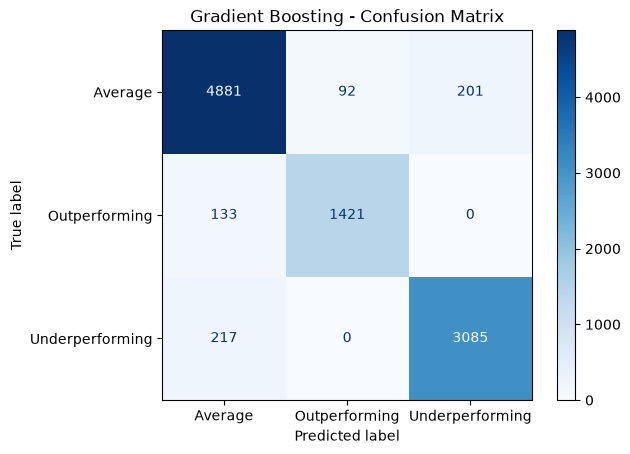

In [20]:
from sklearn.metrics import ConfusionMatrixDisplay

class_labels = [
    "Average",
    "Outperforming",
    "Underperforming"
]

gb_cm = confusion_matrix(y_test, best_pred_3, labels=class_labels)
gb_display = ConfusionMatrixDisplay(confusion_matrix=gb_cm, display_labels=class_labels)
gb_display.plot(cmap="Blues", values_format="d")
plt.title("Gradient Boosting - Confusion Matrix")
plt.show()


In [21]:
results = []

for name, predictions in [
    ("LDA + Logistic Regression", best_pred_1),
    ("Random Forest", best_pred_2),
    ("Gradient Boosting", best_pred_3)
]:
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, average="weighted"),
        "Recall": recall_score(y_test, predictions, average="weighted"),
        "Weighted F1": f1_score(y_test, predictions, average="weighted"),
        "Macro F1": f1_score(y_test, predictions, average="macro"),
        "Balanced Accuracy": balanced_accuracy_score(y_test, predictions)
    })

comparison_df = pd.DataFrame(results)

comparison_df.to_csv("model_comparison_updated.csv", index=False)

comparison_df

,Model,Accuracy,Precision,Recall,Weighted F1,Macro F1,Balanced Accuracy
0,LDA + Logistic Regression,0.734696,0.736938,0.734696,0.733723,0.723110,0.705961
1,Random Forest,0.933001,0.933119,0.933001,0.932898,0.928730,0.922619
2,Gradient Boosting,0.935892,0.935926,0.935892,0.935867,0.933798,0.930689


In [ ]:
importance = permutation_importance(
    best_model_3,
    X_test,
    y_test,
    n_repeats=3,
    random_state=42,
    scoring="f1_weighted",
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": features,
    "Importance": importance.importances_mean
})

importance_df = importance_df.sort_values(by="Importance", ascending=False)
print(importance_df)

                Feature    Importance
2   market_value_in_eur  3.114298e-01
6         total_assists  5.534337e-02
5           total_goals  5.319682e-02
4         total_minutes  3.458997e-02
1    international_caps  1.309516e-02
3        matches_played  1.297024e-02
12     competition_code  3.518398e-03
7          yellow_cards  4.651113e-04
13        confederation  3.990498e-04
8             red_cards  9.987653e-05
11                 foot  0.000000e+00
0          height_in_cm -4.277720e-07
10         sub_position -1.319289e-04
9              position -1.993396e-04


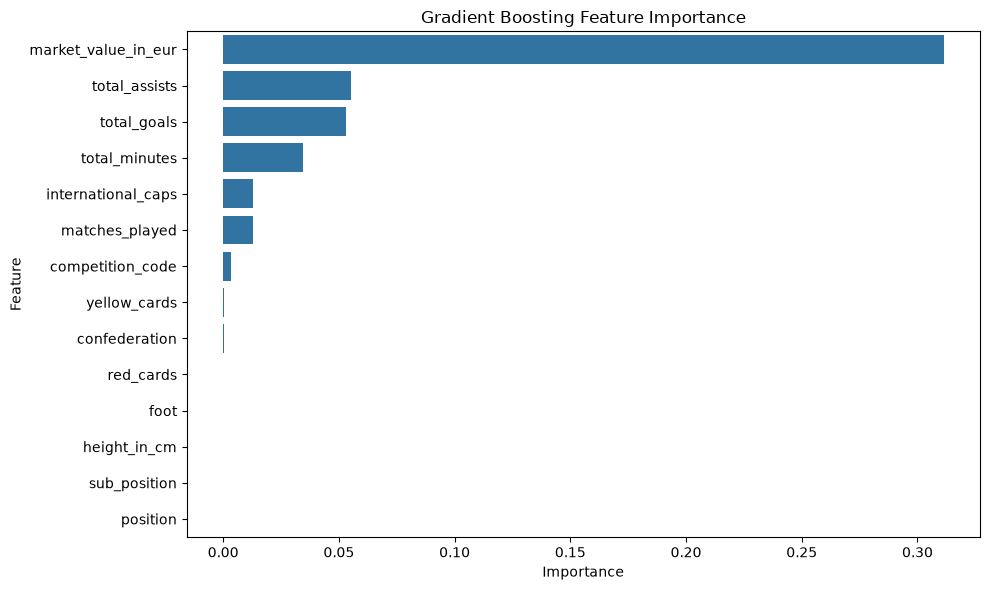

In [23]:
plt.figure(figsize=(10, 6))
sns.barplot(data=importance_df, x="Importance", y="Feature")
plt.title("Gradient Boosting Feature Importance")
plt.tight_layout()
plt.show()

In [24]:
joblib.dump(best_model_1, "lda_logistic_model.pkl")
joblib.dump(best_model_2, "random_forest_model.pkl")
joblib.dump(best_model_3, "gradient_boosting_model.pkl")
print("All models and model_comparison_updated.csv file saved successfully!")

All models and model_comparison_updated.csv file saved successfully!


In [25]:
final_model = best_model_3 
joblib.dump(final_model, "model.pkl")
print("Final Gradient Boosting model saved successfully!")

Final Gradient Boosting model saved successfully!


### Note on Target Definition (Stage 1 Composite Rating)

The target `Player_Future_Potential_Rating` is a Stage-1 composite rating generated from same-snapshot Transfermarkt statistics using percentile ranks. Five of the seven features used to generate this rating overlap with our 14 model input features.

Therefore, the models are learning to reproduce the approved composite rating rather than directly predicting independently observed future player performance.

Gradient Boosting achieved 93.59% test accuracy, demonstrating strong reproduction of this composite rating. This result should not be interpreted as proof of 93.59% accuracy in predicting actual future football performance.